# Người B — Hình học cảnh, hiệu chuẩn BEV và phân tích không gian

Notebook chạy trên máy (CPU), dữ liệu nằm sẵn trong repo (`Data/VnTraffic/AICC22-Custom`).
Toàn bộ thuật toán nằm trong package `src/bevtraffic`, notebook chỉ gọi lại và trực quan hoá.

**Thay đổi so với bản trước:** bản cũ tự sinh 8 điểm hiệu chuẩn từ một hình thang chọn tay rồi cộng nhiễu 0.55 px,
nên RMSE 0.872 px chỉ là nhiễu tự thêm. Các phép kiểm "bề rộng làn 3.66 m", "đếm 0 %", "Precision 1.0" cũng tự so với chính nó.
Bản này dùng hiệu chuẩn độc lập của camera (AI City Challenge, toạ độ GPS) và đánh giá lại bằng nhãn người gán.

Nội dung:
1. Dữ liệu, nền tĩnh (temporal median), CLAHE
2. Dò vạch kẻ đường (HLS → Canny → HoughLinesP) và điểm tụ
3. Hiệu chuẩn homography: hiệu chuẩn GPS của AI City so với hình thang đoán tay
4. Phân tích không gian trên BEV: tốc độ, đếm xe, khoảng cách thời gian (THW), bản đồ ùn tắc
5. Đánh giá tốc độ theo từng xe

In [1]:
import sys, json
from pathlib import Path
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "B" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bevtraffic import preprocess, lanes
from bevtraffic.calibration import Calibration
from bevtraffic.analytics import analyse
from bevtraffic.evaluation import load_mot_txt, gt_to_records, estimate_frame_offset, records_by_frame
from bevtraffic.viz import calibration_sheet, draw_bev_grid

DATA = ROOT / "Data" / "VnTraffic" / "AICC22-Custom"
VID = DATA / "AICC22-Custom_Original-video.mp4"
OUT = ROOT / "outputs" / "B"; OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 100
info = preprocess.video_info(VID); info

{'fps': 10.0, 'frames': 200, 'width': 1280, 'height': 720}

## 1. Nền tĩnh và tăng tương phản
Lấy 100 frame cách đều, tính trung vị theo thời gian cho từng điểm ảnh. Xe chạy qua chiếm điểm ảnh ít hơn một nửa số mẫu
nên bị loại; xe đứng yên cả video (đèn đỏ) vẫn còn trong nền. CLAHE làm trên kênh L của HLS để giữ màu vạch vàng/trắng.

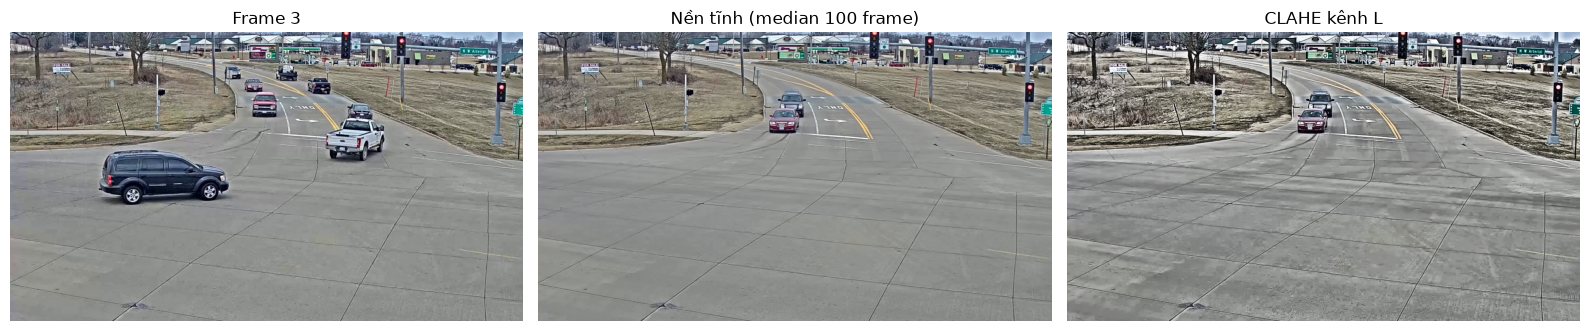

In [2]:
bg = preprocess.median_background(VID, n_samples=100)
bg_eq = preprocess.clahe_lightness(bg)
frame0 = preprocess.read_frame(VID, 3)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
for a, im, t in zip(ax, [frame0, bg, bg_eq], ["Frame 3", "Nền tĩnh (median 100 frame)", "CLAHE kênh L"]):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "b1_background.png", dpi=110); plt.show()

## 2. Vạch kẻ đường và điểm tụ
Mặt nạ màu HLS (trắng: L ≥ 175, S ≤ 110; vàng: H 12–38) → Canny → HoughLinesP trong vùng đường.
Các đoạn chạy dọc đường cắt nhau tại điểm tụ (vanishing point). Điểm tụ dùng để kiểm tra hiệu chuẩn ở mục 3:
một homography đúng phải biến các vạch dọc đường thành các đường song song trên BEV.

116 đoạn Hough, 14 đoạn dùng cho điểm tụ, VP = [707.9 171.5]


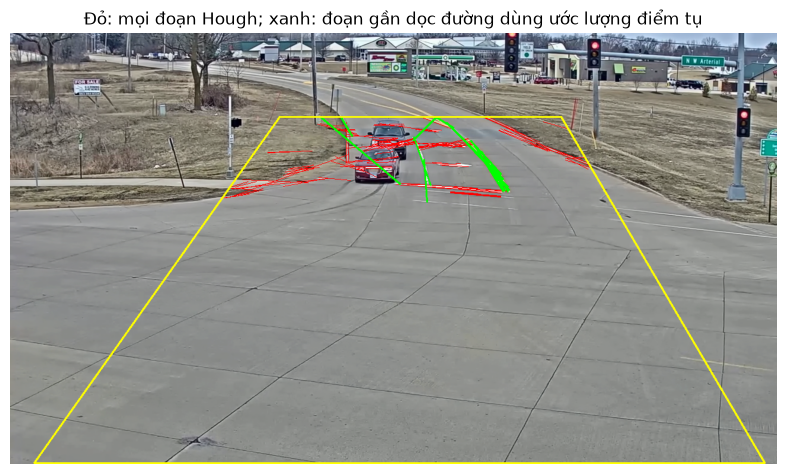

In [3]:
roi = np.array([[450, 140], [920, 140], [1260, 718], [40, 718]])
# mặt đường bê tông sáng: nâng ngưỡng L của mặt nạ trắng lên 215 để chỉ giữ vạch sơn
seg = lanes.hough_segments(bg_eq, roi, white_l=215, min_len=30)
ang = lanes.segment_angles(seg)
road_seg = seg[(np.abs(ang) > 2) & (np.abs(ang) < 60)]
vp, n_used = lanes.vanishing_point(road_seg)
vis = lanes.draw_segments(bg, seg, (0, 0, 255), 1)
vis = lanes.draw_segments(vis, road_seg, (0, 255, 0), 2)
cv2.polylines(vis, [roi.astype(np.int32)], True, (0, 255, 255), 2)
print(f"{len(seg)} đoạn Hough, {n_used} đoạn dùng cho điểm tụ, VP = {np.round(vp, 1)}")
plt.figure(figsize=(10, 5.6)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Đỏ: mọi đoạn Hough; xanh: đoạn gần dọc đường dùng ước lượng điểm tụ")
plt.savefig(OUT / "b2_hough.png", dpi=110, bbox_inches="tight"); plt.show()

## 3. Hiệu chuẩn homography
AICC22-Custom là camera **S01/c002** của AI City Challenge (CityFlow), thu nhỏ từ 1920×1080 về 1280×720
(file GT JSON trỏ tới `train/S01/c002/img1`). Bộ dữ liệu gốc có `calibration.txt`: homography từ (vĩ độ, kinh độ) sang pixel,
sai số chiếu lại 11.4 px ở 1080p. `scripts/make_aic_config.py` đảo ma trận, đổi GPS sang mét (east/north) rồi xoay để đường vào nằm dọc trục y.

So sánh với hình thang mà bản cũ chọn tay và gán kích thước 3 làn × 3.66 m × 24 m:

In [4]:
cal = Calibration.from_yaml(ROOT / "configs/cameras/aicc22_s01_c002.yaml")
trap = np.array([[535, 165], [825, 165], [1120, 700], [100, 700]], float)
w = cal.to_world(trap)
d = lambda a, b: float(np.linalg.norm(w[a] - w[b]))
pd.DataFrame({"cạnh": ["trên", "dưới", "trái", "phải"],
              "bản cũ giả định (m)": [10.98, 10.98, 24.0, 24.0],
              "theo hiệu chuẩn AI City (m)": [d(0, 1), d(3, 2), d(0, 3), d(1, 2)]}).round(1)

,cạnh,bản cũ giả định (m),theo hiệu chuẩn AI City (m)
0,trên,11.0,13.1
1,dưới,11.0,11.4
2,trái,24.0,67.3
3,phải,24.0,66.1


Hình thang thực tế dài khoảng **66 m** chứ không phải 24 m, nên mọi vận tốc dọc đường của bản cũ bị nhỏ đi khoảng 2.7 lần.
Các tấm bê tông mặt đường (mỗi tấm vài mét) và hai mũi tên "ONLY" trên BEV dưới đây có tỷ lệ hợp lý, là một kiểm tra bằng mắt độc lập.

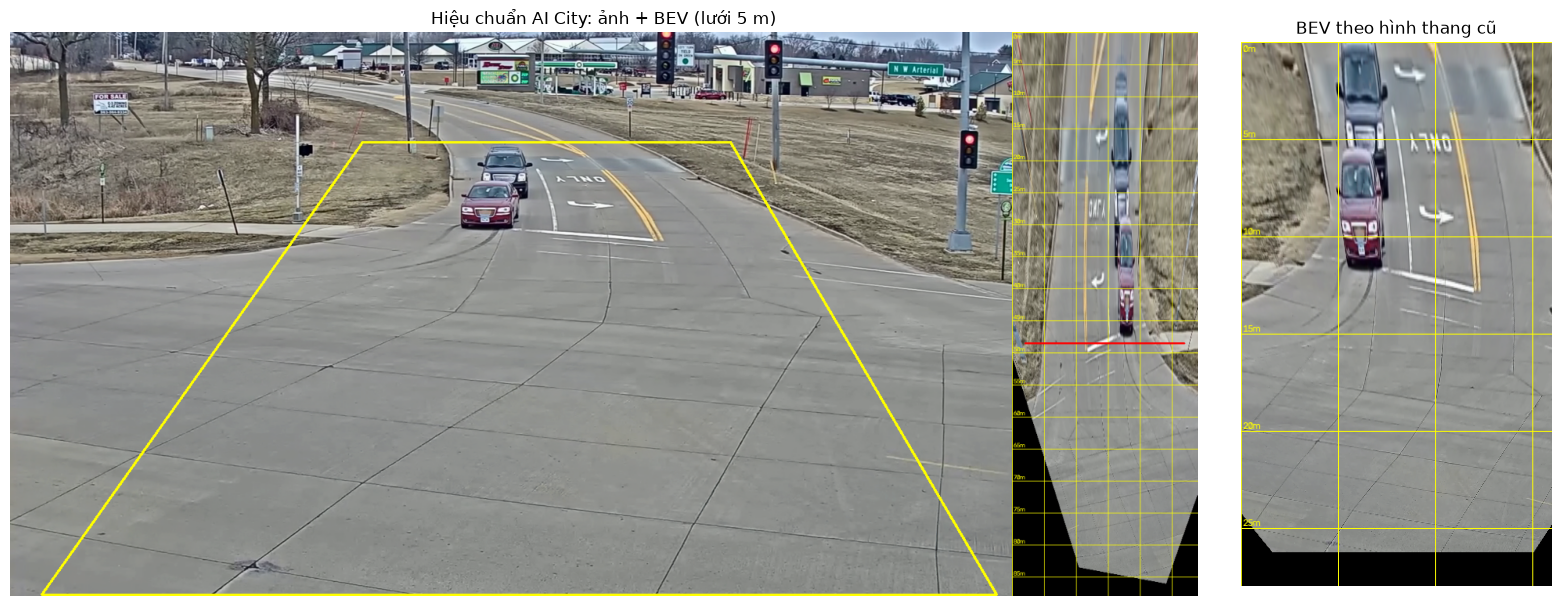

AI City       : 703 đoạn vạch trên BEV, lệch so với trục đường -1.2° ± 6.8°
hình thang cũ : 216 đoạn vạch trên BEV, lệch so với trục đường +4.0° ± 10.0°
Điểm tụ hướng đường suy ra từ hiệu chuẩn AI City: (627, -4); từ Hough (mục 2): (708, 172)
Sai số 1 pixel theo chiều dọc ảnh = 0.03 m ở gần (v=700), 0.55 m ở xa (v=160)


In [5]:
import cv2 as _cv
H_old, _ = _cv.findHomography(trap, np.array([[2.5, 2], [13.48, 2], [13.48, 26], [2.5, 26]]), 0)
old = Calibration(camera_id="old_trapezoid", image_size=(1280, 720), H=H_old, x_range=(0, 16), y_range=(0, 28), px_per_m=20)
sheet = calibration_sheet(bg, cal, OUT / "b3_calibration_aic.jpg")
bev_old = draw_bev_grid(old.warp_bev(bg), old)
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [4, 1]})
ax[0].imshow(cv2.cvtColor(sheet, cv2.COLOR_BGR2RGB)); ax[0].set_title("Hiệu chuẩn AI City: ảnh + BEV (lưới 5 m)"); ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(bev_old, cv2.COLOR_BGR2RGB)); ax[1].set_title("BEV theo hình thang cũ"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(OUT / "b3_bev_compare.png", dpi=110); plt.show()

for name, c in [("AI City", cal), ("hình thang cũ", old)]:
    p = lanes.bev_parallelism(c.warp_bev(bg_eq))
    print(f"{name:14s}: {p.get('n', 0)} đoạn vạch trên BEV, lệch so với trục đường {p.get('mean_dev_deg', float('nan')):+.1f}° ± {p.get('std_dev_deg', float('nan')):.1f}°")
v = np.linalg.inv(cal.H) @ [0, -1, 0]
print("Điểm tụ hướng đường suy ra từ hiệu chuẩn AI City: (%.0f, %.0f); từ Hough (mục 2): (%.0f, %.0f)" % (v[0] / v[2], v[1] / v[2], vp[0], vp[1]))
print("Sai số 1 pixel theo chiều dọc ảnh = %.2f m ở gần (v=700), %.2f m ở xa (v=160)" % (cal.metres_per_pixel(640, 700), cal.metres_per_pixel(640, 160)))

Trên BEV của hiệu chuẩn AI City, các đoạn vạch gần như song song với trục đường (độ lệch nhỏ và tản ít hơn hình thang cũ).
Điểm tụ ước lượng tự động từ Hough lệch so với điểm tụ của hiệu chuẩn: ở cảnh này khe nối tấm bê tông cũng bị bắt thành "vạch"
và đường phía xa cong, nên Hough chỉ dùng để kiểm tra, không đủ tin cậy để tự hiệu chuẩn. Với camera Đà Nẵng
(`scripts/make_danang_config.py`) hiệu chuẩn được dựng từ hai điểm tụ đo trên các vạch kẻ thẳng.

## 4. Phân tích không gian trên BEV
Đầu vào là các bản ghi theo hợp đồng dữ liệu `Data/contracts/schema.json`. Ở đây dùng **khung GT do người gán** (để tách lỗi hình học khỏi lỗi detector)
và track của YOLO26 fine-tune + ByteTrack (`scripts/track.py`).

- Điểm chạm đất = trung điểm cạnh đáy bbox; bỏ các box chạm mép ảnh vì cạnh đáy bị cắt.
- Tốc độ: hồi quy tuyến tính vị trí theo thời gian trong cửa sổ 0.8 s rồi làm mượt EMA (α = 0.3); so sánh với vận tốc 1 bước và Kalman.
- Đếm xe: đoạn quỹ đạo cắt vạch ảo theo đúng chiều, mỗi xe một lần.
- THW: xe sau / xe trước cùng làn, lệch ngang < 1.5 m, tính một lần cho mỗi cặp xe.
- Bản đồ ùn tắc: thời gian dừng (giây) của xe chậm hơn 10 km/h trên mỗi ô BEV.

In [6]:
gt_raw = load_mot_txt(DATA / "AICC22-Custom_GroundTruth.txt", 0)
pred = [json.loads(l) for l in open(ROOT / "outputs/tracks/tracks_aicc22_yolo26_vn_finetuned_bytetrack_vn.jsonl")]
off = estimate_frame_offset(gt_raw, records_by_frame(pred))
print(off.to_string(index=False))
k = int(off.loc[off.mean_best_iou.idxmax(), "offset"]); print("GT frame offset =", k)
gt = load_mot_txt(DATA / "AICC22-Custom_GroundTruth.txt", k)
res_gt = analyse(gt_to_records(gt, info["fps"]), cal)
res_pr = analyse(pred, cal)
pd.DataFrame([res_gt["summary"], res_pr["summary"]], index=["GT boxes", "YOLO26 + ByteTrack"]).T

 offset  mean_best_iou
     -3       0.519784
     -2       0.589545
     -1       0.651374
      0       0.596510
      1       0.525651
      2       0.469018
      3       0.424035
GT frame offset = -1


,GT boxes,YOLO26 + ByteTrack
camera_id,aicc22_s01_c002,aicc22_s01_c002
frames,200,200
records,1185,1147
tracks,21,30
tracks_in_zone,18,21
tracks_moved_5m,16,16
edge_boxes,6,217
counted,1,1
counts_by_tripwire,{'stop_bar': 1},{'stop_bar': 1}
counts_by_class,{'car': 1},{'car': 1}


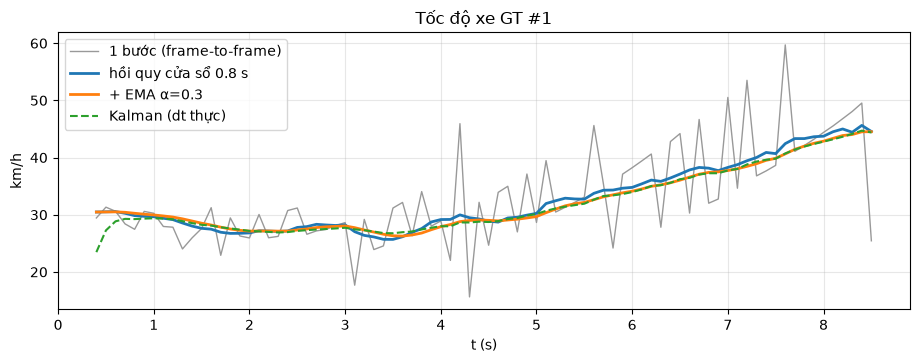

,raw_kmh,win_kmh,ema_kmh,kf_kmh
độ lệch chuẩn trung bình TRONG một track (km/h),8.23,5.48,4.86,6.06


In [7]:
pts = res_gt["points"]
tid = res_gt["tracks"].sort_values("n", ascending=False).query("speed_median_kmh > 15").track_id.iloc[0]
g = pts[(pts.track_id == tid) & pts.win_kmh.notna()]
plt.figure(figsize=(11, 3.6))
plt.plot(g.t, g.raw_kmh, color="0.6", lw=1, label="1 bước (frame-to-frame)")
plt.plot(g.t, g.win_kmh, lw=2, label="hồi quy cửa sổ 0.8 s")
plt.plot(g.t, g.ema_kmh, lw=2, label="+ EMA α=0.3")
plt.plot(g.t, g.kf_kmh, "--", lw=1.5, label="Kalman (dt thực)")
plt.xlabel("t (s)"); plt.ylabel("km/h"); plt.title(f"Tốc độ xe GT #{tid}"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(OUT / "b4_speed_filters.png", dpi=110, bbox_inches="tight"); plt.show()

z = pts[pts.win_kmh.notna()]
pd.DataFrame({c: [z.groupby("track_id")[c].std().mean()] for c in ["raw_kmh", "win_kmh", "ema_kmh", "kf_kmh"]},
             index=["độ lệch chuẩn trung bình TRONG một track (km/h)"]).round(2)

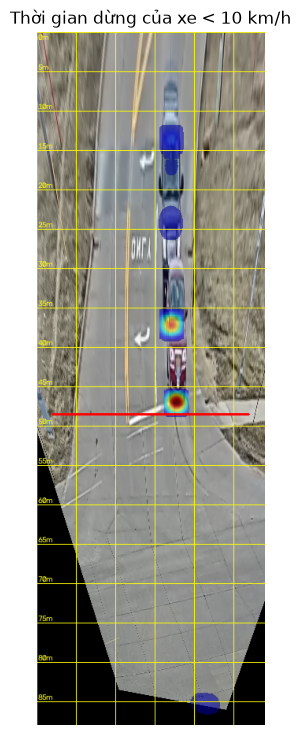

In [8]:
c = res_gt["congestion"]
bev = cal.warp_bev(bg)
if c.max() > 0:
    heat = cv2.applyColorMap(np.uint8(255 * c / c.max()), cv2.COLORMAP_JET)
    m = c > 0.02 * c.max(); bev[m] = cv2.addWeighted(bev, .45, heat, .55, 0)[m]
plt.figure(figsize=(4, 9)); plt.imshow(cv2.cvtColor(draw_bev_grid(bev, cal), cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("Thời gian dừng của xe < 10 km/h"); plt.savefig(OUT / "b4_congestion.png", dpi=110, bbox_inches="tight"); plt.show()

## 5. Đánh giá tốc độ theo từng xe
Tốc độ tham chiếu = khung GT chiếu bằng hiệu chuẩn AI City. Tách hai nguồn sai số:
- **hình học**: cùng khung GT nhưng dùng hình thang cũ;
- **detector/tracker**: track dự đoán (ghép với xe GT bằng IoU) chiếu bằng hiệu chuẩn AI City.

Chạy `python scripts/eval_aicc22.py`; bảng dưới đọc từ `outputs/aicc22/`.

In [9]:
print(json.loads((ROOT / "outputs/aicc22/summary.json").read_text()))
pd.read_csv(ROOT / "outputs/aicc22/speed_eval.csv")

{'gt_frame_offset': -1, 'reference_vehicles': 13, 'reference_speed_median_kmh': 32.80444145659808, 'gt_counted_stop_bar': 1, 'reference_moving_mean_kmh': 28.61332388215328, 'old_geometry_moving_mean_kmh': 14.803903211490985}


,what,vehicles,matched,MAE_kmh,RMSE_kmh,bias_kmh,MAPE_%,counted,tracks
0,"GT boxes, old trapezoid geometry",13,13,10.15,14.83,-10.15,32.29,NaN,NaN
1,"finetuned tracks, AIC geometry",13,11,2.87,4.80,2.13,17.62,1.0,30.0
2,"finetuned tracks, old geometry (old pipeline)",13,11,11.14,16.04,-10.57,32.34,NaN,NaN
3,"coco tracks, AIC geometry",13,13,2.21,5.73,1.27,18.72,1.0,23.0
4,"coco tracks, old geometry (old pipeline)",13,13,9.94,14.76,-9.94,29.67,NaN,NaN


**Nhận xét.** Với hình thang cũ, tốc độ bị đo thấp khoảng 10 km/h trên mỗi xe (≈ 32 %), dù detector hoàn hảo.
Khi dùng hiệu chuẩn độc lập, sai số do detector + tracker còn khoảng 2–3 km/h.
Hạn chế còn lại: hiệu chuẩn GPS của AI City có sai số chiếu lại ~11 px (1080p); cảnh là ngã tư nên phần lớn xe rẽ, đường đi cong,
và chỉ có 200 frame (20 s) với 13 xe chạy, nên các con số chỉ mang tính minh hoạ. Đánh giá tốc độ chính dùng bộ Luvizon (GT cảm biến vòng từ).